In [1]:
import csv

import numpy as np
import tensorflow as tf
from sklearn.model_selection import train_test_split

RANDOM_SEED = 42

# Specify each path

In [2]:
dataset = 'model/keypoint_classifier/keypoint.csv'
model_save_path = 'model/keypoint_classifier/keypoint_classifier.hdf5'

# Set number of classes

In [3]:
NUM_CLASSES = 28

# Dataset reading

In [4]:
X_dataset = np.loadtxt(dataset, delimiter=',', dtype='float32', usecols=list(range(1, (21 * 2) + 1)))

In [5]:
y_dataset = np.loadtxt(dataset, delimiter=',', dtype='int32', usecols=(0))

In [6]:
X_train, X_test, y_train, y_test = train_test_split(X_dataset, y_dataset, train_size=0.75, random_state=RANDOM_SEED)

# Model building

In [7]:
model = tf.keras.models.Sequential([
    tf.keras.layers.Input((21 * 2, )),
    tf.keras.layers.Dropout(0.2),
    tf.keras.layers.Dense(20, activation='relu'),
    tf.keras.layers.Dropout(0.4),
    tf.keras.layers.Dense(10, activation='relu'),
    tf.keras.layers.Dense(NUM_CLASSES, activation='softmax')
])

In [8]:
model.summary()  # tf.keras.utils.plot_model(model, show_shapes=True)

Model: "sequential"
_________________________________________________________________
 Layer (type)                Output Shape              Param #   
 dropout (Dropout)           (None, 42)                0         
                                                                 
 dense (Dense)               (None, 20)                860       
                                                                 
 dropout_1 (Dropout)         (None, 20)                0         
                                                                 
 dense_1 (Dense)             (None, 10)                210       
                                                                 
 dense_2 (Dense)             (None, 28)                308       
                                                                 
Total params: 1378 (5.38 KB)
Trainable params: 1378 (5.38 KB)
Non-trainable params: 0 (0.00 Byte)
_________________________________________________________________


In [9]:
# Model checkpoint callback
cp_callback = tf.keras.callbacks.ModelCheckpoint(
    model_save_path, verbose=1, save_weights_only=False)
# Callback for early stopping
es_callback = tf.keras.callbacks.EarlyStopping(patience=20, verbose=1)

In [10]:
# Model compilation
model.compile(
    optimizer='adam',
    loss='sparse_categorical_crossentropy',
    metrics=['accuracy']
)

# Model training

In [11]:
model.fit(
    X_train,
    y_train,
    epochs=1000,
    batch_size=128,
    validation_data=(X_test, y_test),
    callbacks=[cp_callback, es_callback]
)

Epoch 1/1000
108/113 [===========================>..] - ETA: 0s - loss: 3.0639 - accuracy: 0.1010
Epoch 1: saving model to model/keypoint_classifier\keypoint_classifier.hdf5
113/113 [==============================] - 2s 6ms/step - loss: 3.0503 - accuracy: 0.1036 - val_loss: 2.5526 - val_accuracy: 0.2606
Epoch 2/1000
 31/113 [=======>......................] - ETA: 0s - loss: 2.6106 - accuracy: 0.1857

c:\Users\markl\anaconda3\envs\opencv_env\lib\site-packages\keras\src\engine\training.py:3000: UserWarning: You are saving your model as an HDF5 file via `model.save()`. This file format is considered legacy. We recommend using instead the native Keras format, e.g. `model.save('my_model.keras')`.
  saving_api.save_model(


 98/113 [=========================>....] - ETA: 0s - loss: 2.4446 - accuracy: 0.2174
Epoch 2: saving model to model/keypoint_classifier\keypoint_classifier.hdf5
113/113 [==============================] - 0s 4ms/step - loss: 2.4131 - accuracy: 0.2212 - val_loss: 1.9099 - val_accuracy: 0.3842
Epoch 3/1000
 99/113 [=========================>....] - ETA: 0s - loss: 2.0018 - accuracy: 0.3038
Epoch 3: saving model to model/keypoint_classifier\keypoint_classifier.hdf5
113/113 [==============================] - 0s 3ms/step - loss: 1.9805 - accuracy: 0.3073 - val_loss: 1.5504 - val_accuracy: 0.6553
Epoch 4/1000
111/113 [============================>.] - ETA: 0s - loss: 1.7362 - accuracy: 0.3721
Epoch 4: saving model to model/keypoint_classifier\keypoint_classifier.hdf5
113/113 [==============================] - 0s 3ms/step - loss: 1.7344 - accuracy: 0.3726 - val_loss: 1.3270 - val_accuracy: 0.7204
Epoch 5/1000
108/113 [===========================>..] - ETA: 0s - loss: 1.6213 - accuracy: 0.3981


In [12]:
# Model evaluation
val_loss, val_acc = model.evaluate(X_test, y_test, batch_size=128)

38/38 [==============================] - 0s 2ms/step - loss: 0.3001 - accuracy: 0.9726


In [13]:
# Loading the saved model

model = tf.keras.models.load_model(model_save_path)

In [14]:
# Inference test
predict_result = model.predict(np.array([X_test[0]]))
print(np.squeeze(predict_result))
print(np.argmax(np.squeeze(predict_result)))

1/1 [==============================] - 0s 132ms/step
[1.5372853e-01 2.0081062e-02 4.7892411e-03 5.3930609e-03 3.9072793e-02
 1.3062195e-04 7.5666142e-01 8.4978801e-06 5.8020008e-12 1.5536124e-21
 1.4443498e-03 3.2115574e-10 4.9730770e-06 3.8966811e-17 1.7784605e-02
 1.6506311e-07 2.2503134e-07 7.0752794e-05 8.2979212e-04 5.5536092e-20
 2.7695037e-24 1.5717931e-22 3.1572990e-19 9.6637941e-23 2.7617809e-24
 1.2126062e-22 1.1429380e-22 2.1427024e-18]
6


# Confusion matrix

150/150 [==============================] - 0s 1ms/step


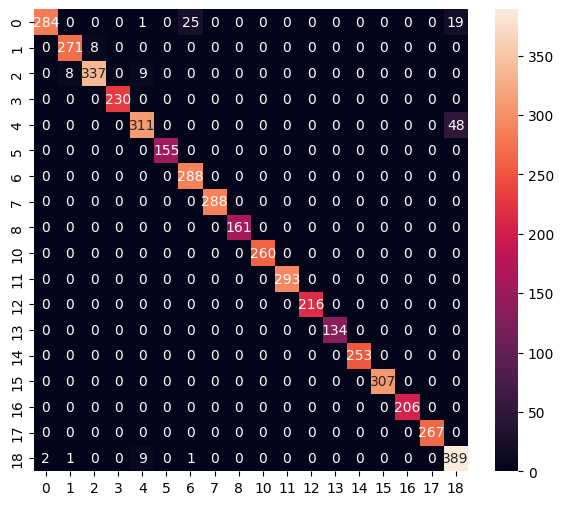

Classification Report
              precision    recall  f1-score   support

           0       0.99      0.86      0.92       329
           1       0.97      0.97      0.97       279
           2       0.98      0.95      0.96       354
           3       1.00      1.00      1.00       230
           4       0.94      0.87      0.90       359
           5       1.00      1.00      1.00       155
           6       0.92      1.00      0.96       288
           7       1.00      1.00      1.00       288
           8       1.00      1.00      1.00       161
          10       1.00      1.00      1.00       260
          11       1.00      1.00      1.00       293
          12       1.00      1.00      1.00       216
          13       1.00      1.00      1.00       134
          14       1.00      1.00      1.00       253
          15       1.00      1.00      1.00       307
          16       1.00      1.00      1.00       206
          17       1.00      1.00      1.00       267
     

In [15]:
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt
from sklearn.metrics import confusion_matrix, classification_report

def print_confusion_matrix(y_true, y_pred, report=True):
    labels = sorted(list(set(y_true)))
    cmx_data = confusion_matrix(y_true, y_pred, labels=labels)
    
    df_cmx = pd.DataFrame(cmx_data, index=labels, columns=labels)
 
    fig, ax = plt.subplots(figsize=(7, 6))
    sns.heatmap(df_cmx, annot=True, fmt='g' ,square=False)
    ax.set_ylim(len(set(y_true)), 0)
    plt.show()
    
    if report:
        print('Classification Report')
        print(classification_report(y_test, y_pred))

Y_pred = model.predict(X_test)
y_pred = np.argmax(Y_pred, axis=1)

print_confusion_matrix(y_test, y_pred)

# Convert to model for Tensorflow-Lite

In [16]:
# Save as a model dedicated to inference
model.save(model_save_path, include_optimizer=False)

c:\Users\markl\anaconda3\envs\opencv_env\lib\site-packages\keras\src\engine\training.py:3000: UserWarning: You are saving your model as an HDF5 file via `model.save()`. This file format is considered legacy. We recommend using instead the native Keras format, e.g. `model.save('my_model.keras')`.
  saving_api.save_model(


In [17]:
# Transform model (quantization)
tflite_save_path = 'model/keypoint_classifier/keypoint_classifier.tflite'

converter = tf.lite.TFLiteConverter.from_keras_model(model)
converter.optimizations = [tf.lite.Optimize.DEFAULT]
tflite_quantized_model = converter.convert()

open(tflite_save_path, 'wb').write(tflite_quantized_model)

INFO:tensorflow:Assets written to: C:\Users\markl\AppData\Local\Temp\tmpm97y2l3z\assets


INFO:tensorflow:Assets written to: C:\Users\markl\AppData\Local\Temp\tmpm97y2l3z\assets


7600

# Inference test

In [18]:
interpreter = tf.lite.Interpreter(model_path=tflite_save_path)
interpreter.allocate_tensors()

In [19]:
# Get I / O tensor
input_details = interpreter.get_input_details()
output_details = interpreter.get_output_details()

In [20]:
interpreter.set_tensor(input_details[0]['index'], np.array([X_test[0]]))

In [21]:
%%time
# Inference implementation
interpreter.invoke()
tflite_results = interpreter.get_tensor(output_details[0]['index'])

CPU times: total: 0 ns
Wall time: 0 ns


In [22]:
print(np.squeeze(tflite_results))
print(np.argmax(np.squeeze(tflite_results)))

[1.5372854e-01 2.0081120e-02 4.7892407e-03 5.3930678e-03 3.9072782e-02
 1.3062193e-04 7.5666136e-01 8.4978965e-06 5.8019670e-12 1.5536121e-21
 1.4443578e-03 3.2115510e-10 4.9730852e-06 3.8966808e-17 1.7784588e-02
 1.6506341e-07 2.2503131e-07 7.0753129e-05 8.2979235e-04 5.5536305e-20
 2.7695348e-24 1.5717989e-22 3.1573109e-19 9.6638661e-23 2.7617908e-24
 1.2126107e-22 1.1429465e-22 2.1427185e-18]
6
